# Phase 2 — Qualité et nettoyage des données

**Objectif :** auditer le dataset brut *sans le modifier*, identifier chaque problème de qualité, et prendre une **décision justifiée** pour chacun.
Les décisions sont ensuite implémentées dans `src/churn/data.py` (code réutilisable et testé), puis appliquées en fin de notebook.

**Plan**
1. Chargement et vue d'ensemble
2. Valeurs manquantes (explicites et cachées)
3. Doublons
4. Cohérence entre variables
5. Modalités des variables catégorielles
6. Valeurs aberrantes
7. Variable cible
8. Synthèse des décisions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.config import RAW_DATA_FILE, TARGET, ID_COL
from churn.viz import set_style, save_fig, BLUE, CHURN_COLORS, CHURN_LABELS, TEXT, TEXT_SECONDARY

set_style()
pd.set_option("display.max_columns", 30)

## 1. Chargement et vue d'ensemble

In [2]:
raw = pd.read_csv(RAW_DATA_FILE)
print(f"{raw.shape[0]:,} lignes × {raw.shape[1]} colonnes".replace(",", " "))
raw.head()

7 043 lignes × 21 colonnes


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Constat :** 18 colonnes texte, 3 numériques. `SeniorCitizen` est numérique (0/1) alors que les autres variables binaires sont en `Yes`/`No`.
⚠️ **`TotalCharges` est de type texte** alors qu'il s'agit d'un montant : c'est le signe que certaines valeurs ne sont pas des nombres.

## 2. Valeurs manquantes

In [4]:
print("Valeurs manquantes détectées par isna() :", raw.isna().sum().sum())

Valeurs manquantes détectées par isna() : 0


`isna()` ne trouve rien… mais le type texte de `TotalCharges` est suspect. Cherchons les **valeurs manquantes cachées** : chaînes vides ou composées d'espaces.

In [5]:
text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
hidden_na = {c: int(raw[c].astype(str).str.strip().eq("").sum()) for c in text_cols}
{c: n for c, n in hidden_na.items() if n > 0}

{'TotalCharges': 11}

In [6]:
total_num = pd.to_numeric(raw["TotalCharges"], errors="coerce")
raw.loc[total_num.isna(), [ID_COL, "tenure", "MonthlyCharges", "TotalCharges", "Contract", TARGET]]

,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


In [7]:
print("Clients avec tenure = 0 :", (raw["tenure"] == 0).sum())
print("Tous les TotalCharges vides correspondent à tenure = 0 :",
      raw.loc[total_num.isna(), "tenure"].eq(0).all())

Clients avec tenure = 0 : 11
Tous les TotalCharges vides correspondent à tenure = 0 : True


**Constat :** 11 valeurs de `TotalCharges` valent `" "` (un espace). Elles correspondent **exactement** aux 11 clients ayant une ancienneté de 0 mois.

**Interprétation :** ce sont des clients arrivés ce mois-ci, **pas encore facturés**. La valeur n'est pas inconnue : elle est logiquement nulle.

**Décision :** convertir `TotalCharges` en numérique et remplacer ces 11 valeurs par **0**.
- ❌ Supprimer les lignes : on perdrait des clients réels (et le cas « nouveau client » existera en production).
- ❌ Imputer par la moyenne (~2 280 $) : absurde pour un client qui n'a jamais payé.

## 3. Doublons

In [8]:
print("Lignes strictement identiques :", raw.duplicated().sum())
print("Identifiants clients en double :", raw[ID_COL].duplicated().sum())
dup_mask = raw.drop(columns=ID_COL).duplicated(keep=False)
print("Lignes identiques en ignorant l'identifiant :", raw.drop(columns=ID_COL).duplicated().sum())

Lignes strictement identiques : 0
Identifiants clients en double : 0
Lignes identiques en ignorant l'identifiant : 22


In [9]:
raw.loc[dup_mask, ["tenure", "PhoneService", "InternetService", "Contract", "MonthlyCharges", TARGET]] \
   .value_counts().head(8)

tenure  PhoneService  InternetService  Contract        MonthlyCharges  Churn
1       Yes           No               Month-to-month  20.45           No       4
                                                       20.20           No       3
                                                       20.05           No       3
                                                       20.15           Yes      2
                                                       19.55           No       2
                      DSL              Month-to-month  45.70           Yes      2
                      Fiber optic      Month-to-month  69.90           Yes      2
                      DSL              Month-to-month  45.30           Yes      2
Name: count, dtype: int64

**Constat :** aucun doublon réel (identifiants uniques). 22 lignes ont le même profil qu'une autre en ignorant l'identifiant : ce sont des clients **différents** aux profils simples et fréquents (ancienneté courte, offres de base).

**Décision :** **conserver** ces lignes. Les supprimer effacerait de vrais clients et biaiserait la représentation des profils simples.

## 4. Cohérence entre variables

**Contrôle 1 :** le montant total facturé devrait être proche de `ancienneté × facture mensuelle` (aux changements de tarif près).

In [10]:
mask = raw["tenure"] > 0
expected = raw.loc[mask, "tenure"] * raw.loc[mask, "MonthlyCharges"]
rel_gap = (total_num[mask] - expected).abs() / total_num[mask]
print(f"Écart relatif médian : {rel_gap.median():.1%}   |   95e percentile : {rel_gap.quantile(.95):.1%}")
print(f"Corrélation : {np.corrcoef(total_num[mask], expected)[0, 1]:.3f}")

Écart relatif médian : 2.0%   |   95e percentile : 10.5%
Corrélation : 1.000


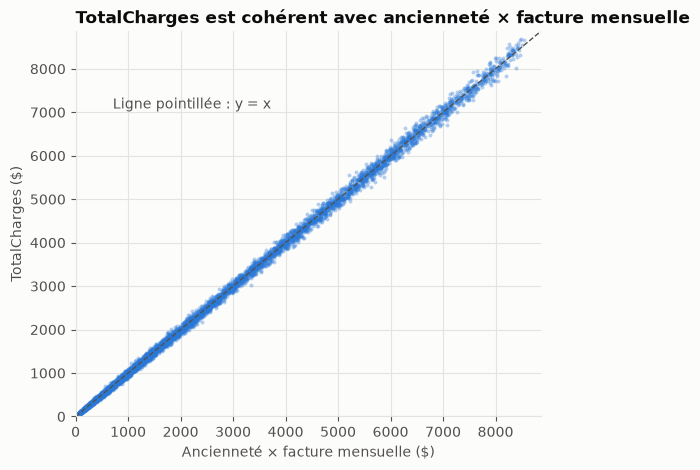

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(expected, total_num[mask], s=8, alpha=0.35, color=BLUE, linewidths=0)
lim = [0, max(expected.max(), total_num.max()) * 1.02]
ax.plot(lim, lim, color=TEXT_SECONDARY, lw=1, ls="--")
ax.annotate("Ligne pointillée : y = x", xy=(lim[1] * 0.08, lim[1] * 0.80), color=TEXT_SECONDARY)
ax.set(xlim=lim, ylim=lim, xlabel="Ancienneté × facture mensuelle ($)", ylabel="TotalCharges ($)")
ax.set_title("TotalCharges est cohérent avec ancienneté × facture mensuelle")
save_fig(fig, "02_coherence_totalcharges.png")
plt.show()

**Constat :** les points suivent la diagonale (écart médian ~2 %, dû aux évolutions de tarif). Les données sont **cohérentes**.

**À retenir pour la Phase 4 :** `TotalCharges` est presque entièrement expliqué par `tenure × MonthlyCharges`, une **redondance** à gérer (multicolinéarité pour la régression logistique).

**Contrôle 2 :** les modalités « No internet service » / « No phone service » doivent correspondre exactement à l'absence du service principal.

In [12]:
internet_opts = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = raw["InternetService"].eq("No")
incoh_internet = (no_internet != raw[internet_opts].eq("No internet service").all(axis=1)).sum()
incoh_phone = (raw["PhoneService"].eq("No") != raw["MultipleLines"].eq("No phone service")).sum()
print("Incohérences internet :", incoh_internet, "| Incohérences téléphone :", incoh_phone)

Incohérences internet : 0 | Incohérences téléphone : 0


**Constat :** 0 incohérence. La modalité « No internet service » est une information **redondante** avec `InternetService = No`. On la garde telle quelle à ce stade ; son encodage sera traité en Phase 4.

## 5. Modalités des variables catégorielles

In [13]:
cat_cols = [c for c in text_cols if c not in (ID_COL, "TotalCharges")]
pd.DataFrame({
    "nb_modalités": [raw[c].nunique() for c in cat_cols],
    "modalités": [sorted(raw[c].unique()) for c in cat_cols],
}, index=cat_cols)

,nb_modalités,modalités
gender,2,"[Female, Male]"
Partner,2,"[No, Yes]"
Dependents,2,"[No, Yes]"
PhoneService,2,"[No, Yes]"
MultipleLines,3,"[No, No phone service, Yes]"
InternetService,3,"[DSL, Fiber optic, No]"
OnlineSecurity,3,"[No, No internet service, Yes]"
OnlineBackup,3,"[No, No internet service, Yes]"
DeviceProtection,3,"[No, No internet service, Yes]"
TechSupport,3,"[No, No internet service, Yes]"


**Constat :** pas de faute de frappe ni de casse incohérente (« yes » vs « Yes »), peu de modalités par variable (2 à 4).

**Décision :** harmoniser `SeniorCitizen` (0/1 → `No`/`Yes`) pour que toutes les variables binaires suivent le même format, et typer ces colonnes en `category` (plus léger en mémoire, intention explicite).

## 6. Valeurs aberrantes

In [14]:
num = raw[["tenure", "MonthlyCharges"]].assign(TotalCharges=total_num)
num.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.4,24.6,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.8,30.1,18.2,35.5,70.4,89.8,118.8
TotalCharges,7032.0,2283.3,2266.8,18.8,401.4,1397.5,3794.7,8684.8


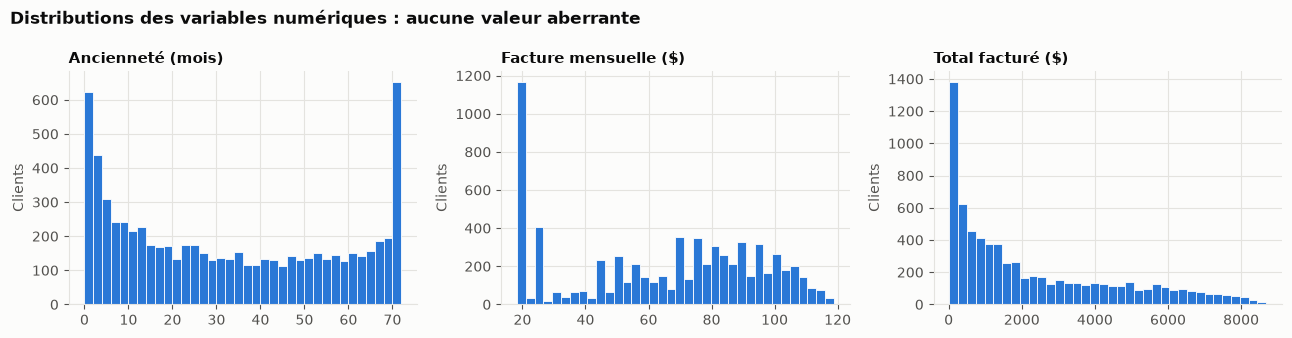

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
labels = {"tenure": "Ancienneté (mois)", "MonthlyCharges": "Facture mensuelle ($)", "TotalCharges": "Total facturé ($)"}
for ax, col in zip(axes, num.columns):
    ax.hist(num[col].dropna(), bins=36, color=BLUE, edgecolor="white", linewidth=0.6)
    ax.set_title(labels[col], fontsize=11)
    ax.set_ylabel("Clients")
fig.suptitle("Distributions des variables numériques : aucune valeur aberrante", x=0.01, ha="left",
             fontweight="bold", color=TEXT)
fig.tight_layout()
save_fig(fig, "02_distributions_numeriques.png")
plt.show()

**Constat :** toutes les valeurs sont plausibles (ancienneté 0–72 mois, facture 18–119 $). Les distributions ne sont pas gaussiennes mais il n'y a **pas d'aberration** :
- `tenure` est bimodale : beaucoup de clients très récents *et* beaucoup de clients très anciens (plafond à 72 mois = 6 ans) ;
- `MonthlyCharges` a un pic autour de 20 $ (offres téléphone seul) ;
- `TotalCharges` est très asymétrique (logique : cumul dans le temps).

**Décision :** aucune suppression. L'asymétrie sera prise en compte en Phase 4 (mise à l'échelle).

## 7. Variable cible

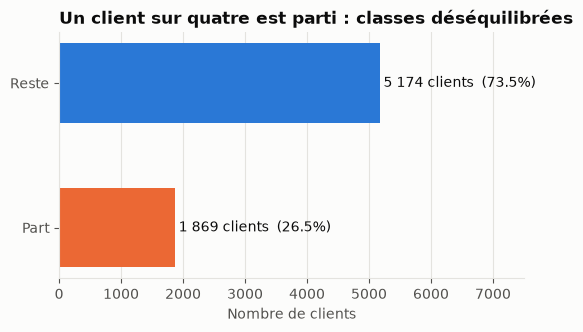

In [16]:
counts = raw[TARGET].map({"No": 0, "Yes": 1}).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh([CHURN_LABELS[i] for i in counts.index], counts.values,
               color=[CHURN_COLORS[i] for i in counts.index], height=0.55)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_width() + 60, bar.get_y() + bar.get_height() / 2,
            f"{n:,} clients  ({n / counts.sum():.1%})".replace(",", " "), va="center", color=TEXT)
ax.set_xlim(0, counts.max() * 1.45)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Nombre de clients")
ax.set_title("Un client sur quatre est parti : classes déséquilibrées")
save_fig(fig, "02_distribution_cible.png")
plt.show()

**Constat :** 26,5 % de churn. Les classes sont **déséquilibrées** (ratio ~1:2,8), sans être extrêmes.

**Conséquences pour la suite :**
- découpage train/test **stratifié** (même proportion de churners dans chaque jeu) ;
- métriques adaptées (PR-AUC, recall, gain net) plutôt que l'accuracy ;
- cible encodée en **1 = part, 0 = reste**.

## 8. Synthèse des décisions de nettoyage

| # | Problème constaté | Décision | Justification |
|---|---|---|---|
| 1 | `TotalCharges` typé texte | Conversion en numérique | C'est un montant |
| 2 | 11 `TotalCharges` = `" "` (valeurs manquantes cachées) | Remplacer par **0** | Tous ont `tenure = 0` : nouveaux clients pas encore facturés |
| 3 | 22 profils identiques (hors identifiant) | **Conserver** | Clients distincts aux profils fréquents |
| 4 | `SeniorCitizen` en 0/1, les autres binaires en Yes/No | Harmoniser en `No`/`Yes` | Cohérence du format |
| 5 | Colonnes catégorielles en texte libre | Typage `category` | Intention explicite, mémoire réduite |
| 6 | Cible `Churn` en Yes/No | Encodage **1 = part / 0 = reste** | Format attendu par les modèles |
| 7 | `customerID` | Passé en **index** | Identifiant, pas une variable explicative (mais conservé pour la traçabilité) |
| — | Redondance `TotalCharges` ≈ `tenure × MonthlyCharges` | *Reporté en Phase 4* | Relève du feature engineering |
| — | Modalités « No internet/phone service » | *Reporté en Phase 4* | Relève de l'encodage |

Ces décisions sont implémentées dans [`src/churn/data.py`](../src/churn/data.py).

## 9. Application du nettoyage

On utilise les fonctions du package (`churn.data`) plutôt que de réécrire le nettoyage ici : c'est **exactement le même code** qui sera utilisé par l'application Streamlit.

In [17]:
from churn.data import load_clean, save_processed

df = load_clean()
print(f"Données nettoyées : {df.shape[0]} clients × {df.shape[1]} colonnes")
print("Valeurs manquantes :", int(df.isna().sum().sum()))
df.head()

Données nettoyées : 7043 clients × 20 colonnes
Valeurs manquantes : 0


,tenure,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
customerID,,,,,,,,,,,,,,,,,,,,
7590-VHVEG,1,29.85,29.85,Female,No,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,0
5575-GNVDE,34,56.95,1889.50,Male,No,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,0
3668-QPYBK,2,53.85,108.15,Male,No,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,1
7795-CFOCW,45,42.30,1840.75,Male,No,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),0
9237-HQITU,2,70.70,151.65,Female,No,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,1


In [18]:
# Avant / après sur les points corrigés
comparison = pd.DataFrame({
    "type avant": raw.drop(columns=ID_COL).dtypes.astype(str),
    "type après": df.dtypes.astype(str),
})
comparison.loc[["TotalCharges", "SeniorCitizen", "Contract", TARGET]]

,type avant,type après
TotalCharges,str,float64
SeniorCitizen,int64,category
Contract,str,category
Churn,str,int8


In [19]:
# Les 11 nouveaux clients : TotalCharges vaut maintenant 0
df.loc[df["tenure"].eq(0), ["tenure", "MonthlyCharges", "TotalCharges", TARGET]]

,tenure,MonthlyCharges,TotalCharges,Churn
customerID,,,,
4472-LVYGI,0,52.55,0.0,0
3115-CZMZD,0,20.25,0.0,0
5709-LVOEQ,0,80.85,0.0,0
4367-NUYAO,0,25.75,0.0,0
1371-DWPAZ,0,56.05,0.0,0
7644-OMVMY,0,19.85,0.0,0
3213-VVOLG,0,25.35,0.0,0
2520-SGTTA,0,20.00,0.0,0
2923-ARZLG,0,19.70,0.0,0


In [20]:
path = save_processed(df)
print("Sauvegardé :", path.relative_to(path.parents[2]))

# Contrôle : la relecture conserve bien les types
reloaded = pd.read_parquet(path)
assert reloaded.dtypes.equals(df.dtypes) and reloaded.shape == df.shape
print("Relecture OK : types et dimensions conservés")

Sauvegardé : data\processed\churn_clean.parquet
Relecture OK : types et dimensions conservés


## Conclusion de la Phase 2

- Le dataset contenait **un piège** : 11 valeurs manquantes cachées (`" "`) dans `TotalCharges`, invisibles pour `isna()`.
- Leur analyse a montré qu'il s'agissait de **nouveaux clients non encore facturés** → valeur 0, décision métier plutôt qu'imputation statistique.
- Aucun doublon réel, aucune valeur aberrante, données cohérentes.
- Le jeu nettoyé (7 043 clients, 19 variables explicatives + cible) est prêt pour l'**analyse exploratoire** (Phase 3).
- Le nettoyage est **industrialisé** (`src/churn/data.py`) et **testé** (`tests/test_data.py`), donc réutilisable tel quel par l'application.